# 🏠 House Price Prediction — Indian Housing Dataset

A beginner-friendly machine learning project: predict the price of a property in India (in **lakhs of rupees**) from details like area, BHK, city and location.

**Dataset:** House Price Prediction Challenge (India) — ~29,000 property listings collected from Indian property portals.
**Problem type:** Regression (predicting a number)

**Steps in this notebook**
1. Load the data
2. Explore it
3. Clean it
4. Create features (including the city, worked out from coordinates)
5. Choose a model using cross-validation, then tune it
6. Evaluate once on the held-out test set
7. See where the model is weak
8. Save a self-contained model and predict on a new house

## Step 1 — Load the data

In [1]:
import sys
sys.path.append("..")   # so we can import from the src/ folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from src.predict import load_bundle, predict_price

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150)

df = pd.read_csv("../data/train.csv")
print("Shape:", df.shape)
df.head()

Shape: (29451, 12)


,POSTED_BY,UNDER_CONSTRUCTION,RERA,BHK_NO.,BHK_OR_RK,SQUARE_FT,READY_TO_MOVE,RESALE,ADDRESS,LONGITUDE,LATITUDE,TARGET(PRICE_IN_LACS)
0,Owner,0,0,2,BHK,1300.236407,1,1,"Ksfc Layout,Bangalore",12.969910,77.597960,55.0
1,Dealer,0,0,2,BHK,1275.000000,1,1,"Vishweshwara Nagar,Mysore",12.274538,76.644605,51.0
2,Owner,0,0,2,BHK,933.159722,1,1,"Jigani,Bangalore",12.778033,77.632191,43.0
3,Owner,0,1,2,BHK,929.921143,1,1,"Sector-1 Vaishali,Ghaziabad",28.642300,77.344500,62.5
4,Dealer,1,0,2,BHK,999.009247,0,1,"New Town,Kolkata",22.592200,88.484911,60.5


## Step 2 — Explore the data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29451 entries, 0 to 29450
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   POSTED_BY              29451 non-null  str    
 1   UNDER_CONSTRUCTION     29451 non-null  int64  
 2   RERA                   29451 non-null  int64  
 3   BHK_NO.                29451 non-null  int64  
 4   BHK_OR_RK              29451 non-null  str    
 5   SQUARE_FT              29451 non-null  float64
 6   READY_TO_MOVE          29451 non-null  int64  
 7   RESALE                 29451 non-null  int64  
 8   ADDRESS                29451 non-null  str    
 9   LONGITUDE              29451 non-null  float64
 10  LATITUDE               29451 non-null  float64
 11  TARGET(PRICE_IN_LACS)  29451 non-null  float64
dtypes: float64(4), int64(5), str(3)
memory usage: 3.5 MB


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

Missing values: 0
Duplicate rows: 401


,count,mean,std,min,25%,50%,75%,max
UNDER_CONSTRUCTION,29451.0,0.179756,3.839908e-01,0.000000,0.000000,0.000000,0.000000,1.000000e+00
RERA,29451.0,0.317918,4.656753e-01,0.000000,0.000000,0.000000,1.000000,1.000000e+00
BHK_NO.,29451.0,2.392279,8.790913e-01,1.000000,2.000000,2.000000,3.000000,2.000000e+01
SQUARE_FT,29451.0,19802.170190,1.901335e+06,3.000000,900.021130,1175.056750,1550.688124,2.545455e+08
READY_TO_MOVE,29451.0,0.820244,3.839908e-01,0.000000,1.000000,1.000000,1.000000,1.000000e+00
RESALE,29451.0,0.929578,2.558613e-01,0.000000,1.000000,1.000000,1.000000,1.000000e+00
LONGITUDE,29451.0,21.300255,6.205306e+00,-37.713008,18.452663,20.750000,26.900926,5.991288e+01
LATITUDE,29451.0,76.837695,1.055775e+01,-121.761248,73.798100,77.324137,77.828740,1.529627e+02
TARGET(PRICE_IN_LACS),29451.0,142.898746,6.568807e+02,0.250000,38.000000,62.000000,100.000000,3.000000e+04


**Things to notice**
- No missing values — nice.
- `SQUARE_FT` goes up to ~254 million and price up to 30,000 lakhs. These are almost certainly data-entry errors (**outliers**).
- There are 401 duplicate rows.
- The columns `LONGITUDE` and `LATITUDE` look swapped (the "longitude" is ~21, the "latitude" is ~77). Indian latitudes are roughly 8–37 and longitudes 68–97, so we'll fix that.

### A warning sign about `SQUARE_FT`
If areas were measured, price divided by area would be an arbitrary decimal. Let's check.

In [4]:
rate = df["TARGET(PRICE_IN_LACS)"] * 1e5 / df["SQUARE_FT"]   # rupees per sq ft
print("Rows where price / area is a whole number of rupees per sq ft:",
      f"{((rate - rate.round()).abs() < 0.01).mean():.1%}")
print("Rows where the area itself is a whole number                 :",
      f"{(df['SQUARE_FT'] == df['SQUARE_FT'].round()).mean():.1%}")

Rows where price / area is a whole number of rupees per sq ft: 100.0%
Rows where the area itself is a whole number                 : 9.9%


Every row has a whole-number rate, but only about 10% have a whole-number area. So `SQUARE_FT` was almost certainly **calculated from the price** and a listed rate, not measured. That means area carries information about the answer, and the scores in this notebook are probably more optimistic than what you would see with areas people type in themselves. We keep the feature (it is the dataset's main numeric input) but treat the results with that caveat.

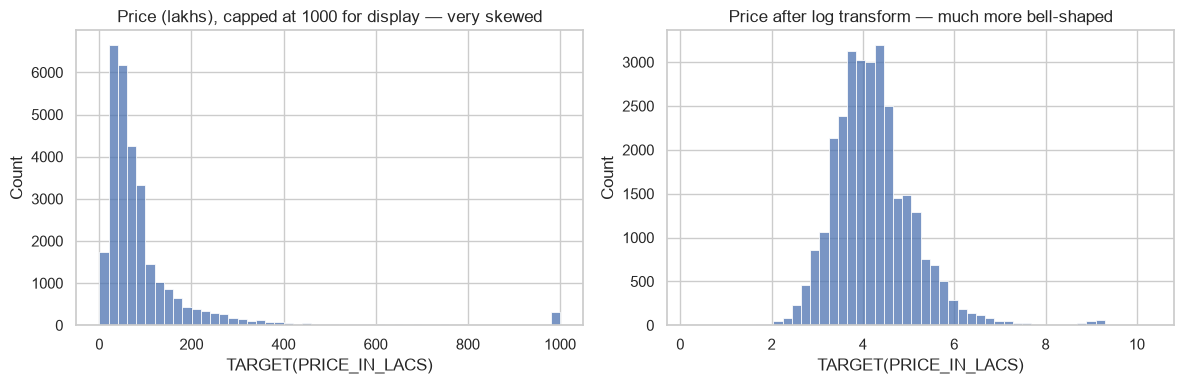

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["TARGET(PRICE_IN_LACS)"].clip(upper=1000), bins=50, ax=axes[0])
axes[0].set_title("Price (lakhs), capped at 1000 for display — very skewed")
sns.histplot(np.log1p(df["TARGET(PRICE_IN_LACS)"]), bins=50, ax=axes[1])
axes[1].set_title("Price after log transform — much more bell-shaped")
plt.tight_layout()
plt.savefig("../images/price_distribution.png", dpi=120)
plt.show()

Prices are heavily right-skewed (a few very expensive homes). Taking the **log** of the price makes it much easier for models to learn from. We'll predict `log(1 + price)` and convert back to lakhs at the end.

## Step 3 — Clean the data
The limits below (200–10,000 sq ft, 5–5,000 lakhs, up to 6 BHK) are **judgement calls** based on looking at the data, not official rules. To be transparent, we count how many rows each rule removes.

In [6]:
data = df.copy()

# 1. Remove duplicate rows
data = data.drop_duplicates()
print("After removing duplicates:", len(data))

# 2. Fix the swapped latitude / longitude columns
data = data.rename(columns={"LONGITUDE": "LATITUDE", "LATITUDE": "LONGITUDE"})

# 3. Rename the target and BHK columns to something easier to type
data = data.rename(columns={"TARGET(PRICE_IN_LACS)": "PRICE_LACS", "BHK_NO.": "BHK"})

# 4. Remove unrealistic values. Each rule is a mask of the rows it would remove.
rules = {
    "area outside 200-10,000 sq ft": ~data["SQUARE_FT"].between(200, 10000),
    "price outside 5-5,000 lakhs":   ~data["PRICE_LACS"].between(5, 5000),
    "more than 6 BHK":               data["BHK"] > 6,
    "coordinates outside India":     ~(data["LATITUDE"].between(6, 37) & data["LONGITUDE"].between(68, 98)),
}
for name, mask in rules.items():
    print(f"{name}: {mask.sum()} rows")

remove = pd.concat(rules.values(), axis=1).any(axis=1)
print(f"\nRows removed in total (rules overlap): {remove.sum()}")
data = data[~remove].copy()
print("Rows left:", len(data))

After removing duplicates: 29050
area outside 200-10,000 sq ft: 221 rows
price outside 5-5,000 lakhs: 154 rows
more than 6 BHK: 42 rows
coordinates outside India: 255 rows

Rows removed in total (rules overlap): 533
Rows left: 28517


## Step 4 — Create features

### Working out the city
The last word of `ADDRESS` is unreliable as a city. For example, listings in Thane, Wadala and Kalyan (all greater Mumbai) are labelled `Lalitpur` or `Maharashtra`. The **coordinates**, however, are reliable, so we assign each listing to the nearest major city centre within a set radius. The centre points and radii below are approximate values I chose; anything not near one of them becomes `Other`.

In [7]:
# name: (latitude, longitude, radius in km) — approximate city centres
CITY_CENTRES = {
    "Mumbai": (19.076, 72.878, 70), "Delhi": (28.614, 77.209, 25),
    "Noida": (28.535, 77.391, 20), "Ghaziabad": (28.667, 77.449, 20),
    "Gurgaon": (28.459, 77.027, 20), "Faridabad": (28.408, 77.318, 20),
    "Sonipat": (28.995, 77.019, 20), "Bhiwadi": (28.210, 76.860, 20),
    "Bangalore": (12.972, 77.594, 40), "Chennai": (13.083, 80.270, 40),
    "Hyderabad": (17.385, 78.487, 45), "Kolkata": (22.573, 88.364, 40),
    "Pune": (18.520, 73.857, 40), "Ahmedabad": (23.023, 72.572, 40),
    "Jaipur": (26.912, 75.787, 30), "Lucknow": (26.847, 80.947, 30),
    "Chandigarh": (30.733, 76.779, 30), "Surat": (21.170, 72.831, 30),
    "Vadodara": (22.307, 73.181, 30), "Nagpur": (21.146, 79.088, 30),
    "Indore": (22.720, 75.858, 30), "Bhopal": (23.259, 77.413, 30),
    "Bhubaneswar": (20.296, 85.825, 30), "Kochi": (9.932, 76.267, 30),
    "Visakhapatnam": (17.687, 83.219, 30), "Coimbatore": (11.017, 76.956, 30),
    "Goa": (15.491, 73.828, 60), "Dehradun": (30.316, 78.032, 30),
    "Mangalore": (12.914, 74.856, 30), "Ranchi": (23.344, 85.310, 30),
    "Guwahati": (26.144, 91.736, 30), "Kanpur": (26.449, 80.332, 30),
    "Mysore": (12.296, 76.639, 30), "Nashik": (19.998, 73.790, 30),
    "Patna": (25.594, 85.138, 30), "Thiruvananthapuram": (8.524, 76.937, 30),
    "Ludhiana": (30.901, 75.857, 30), "Agra": (27.177, 78.008, 30),
    "Vijayawada": (16.506, 80.648, 30), "Raipur": (21.251, 81.630, 30),
    "Jodhpur": (26.238, 73.024, 30),
}

def haversine_km(lat1, lon1, lat2, lon2):
    # Distance between two points on Earth, in km
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

names = np.array(list(CITY_CENTRES))
centres = np.array([v[:2] for v in CITY_CENTRES.values()])
radii = np.array([v[2] for v in CITY_CENTRES.values()])

dist = haversine_km(data["LATITUDE"].values[:, None], data["LONGITUDE"].values[:, None],
                    centres[:, 0][None, :], centres[:, 1][None, :])
dist = np.where(dist <= radii[None, :], dist, np.inf)   # ignore centres that are too far
data["CITY"] = np.where(np.isfinite(dist.min(axis=1)), names[dist.argmin(axis=1)], "Other")

# Cities with very few listings are grouped into "Other"
counts = data["CITY"].value_counts()
data.loc[data["CITY"].isin(counts[counts < 100].index), "CITY"] = "Other"
print(data["CITY"].value_counts())

CITY
Other            5444
Mumbai           4703
Bangalore        3914
Pune             1791
Noida            1733
Kolkata          1623
Chandigarh       1355
Chennai          1138
Jaipur           1030
Ghaziabad         673
Faridabad         641
Vadodara          458
Gurgaon           442
Surat             364
Nagpur            311
Sonipat           292
Lucknow           250
Kochi             245
Bhubaneswar       242
Indore            210
Bhopal            196
Goa               188
Bhiwadi           178
Visakhapatnam     157
Mangalore         132
Coimbatore        128
Ahmedabad         123
Delhi             121
Dehradun          116
Ranchi            113
Vijayawada        106
Hyderabad         100
Name: count, dtype: int64


Sanity check — the old address-based labels that were wrong now land in the right place:

In [8]:
old_label = data["ADDRESS"].str.split(",").str[-1].str.strip()
for bad_label in ["Lalitpur", "Maharashtra"]:
    print(bad_label, "->")
    print(data.loc[old_label == bad_label, "CITY"].value_counts().head(4), "\n")

Lalitpur ->
CITY
Mumbai    1444
Other     1173
Noida       73
Delhi       48
Name: count, dtype: int64 

Maharashtra ->
CITY
Mumbai    1314
Other      150
Pune        52
Nagpur      25
Name: count, dtype: int64 



In [9]:
features = ["POSTED_BY", "CITY", "BHK", "SQUARE_FT", "UNDER_CONSTRUCTION",
            "RERA", "READY_TO_MOVE", "RESALE", "LATITUDE", "LONGITUDE"]

X = pd.get_dummies(data[features], columns=["POSTED_BY", "CITY"], drop_first=True)
y = np.log1p(data["PRICE_LACS"])   # log-transformed target

print("Final feature matrix:", X.shape)
X.head()

Final feature matrix: (28517, 41)


,BHK,SQUARE_FT,UNDER_CONSTRUCTION,RERA,READY_TO_MOVE,RESALE,LATITUDE,LONGITUDE,POSTED_BY_Dealer,POSTED_BY_Owner,...,CITY_Nagpur,CITY_Noida,CITY_Other,CITY_Pune,CITY_Ranchi,CITY_Sonipat,CITY_Surat,CITY_Vadodara,CITY_Vijayawada,CITY_Visakhapatnam
0,2,1300.236407,0,0,1,1,12.969910,77.597960,False,True,...,False,False,False,False,False,False,False,False,False,False
1,2,1275.000000,0,0,1,1,12.274538,76.644605,True,False,...,False,False,True,False,False,False,False,False,False,False
2,2,933.159722,0,0,1,1,12.778033,77.632191,False,True,...,False,False,False,False,False,False,False,False,False,False
3,2,929.921143,0,1,1,1,28.642300,77.344500,False,True,...,False,False,False,False,False,False,False,False,False,False
4,2,999.009247,1,0,0,1,22.592200,88.484911,True,False,...,False,False,False,False,False,False,False,False,False,False


Models only understand numbers, so `get_dummies` (one-hot encoding) turns text columns like `CITY` into 0/1 columns.

In [10]:
# Lock the test set away. We will only use it ONCE, at the very end.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Train rows: 22813 | Test rows: 5704


## Step 5 — Choose a model using cross-validation
To pick a model **without touching the test set**, we use 5-fold cross-validation on the training data only: the training data is split into 5 parts, and each part takes a turn as the validation set.

We compare three models, from simplest to strongest:
1. **Linear Regression** — the baseline
2. **Random Forest** — many decision trees averaged together
3. **Gradient Boosting** — trees that learn from each other's mistakes

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, random_state=42),
}

rows = []
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")
    rows.append({"Model": name, "CV R2 (mean)": scores.mean(), "CV R2 (std)": scores.std()})

cv_df = pd.DataFrame(rows).sort_values("CV R2 (mean)", ascending=False).round(3)
cv_df

,Model,CV R2 (mean),CV R2 (std)
1,Random Forest,0.819,0.009
2,Gradient Boosting,0.803,0.008
0,Linear Regression,0.653,0.024


R² here is measured on **log price** (the scale the models are trained on). The `std` column shows how much the score varies between folds — a small value means the result is stable.

### Tune the best model
Random Forest wins, so we tune two of its settings with `GridSearchCV` (again using only the training data). Note that Gradient Boosting was **not** tuned, so this comparison slightly favours Random Forest.

In [12]:
param_grid = {
    "min_samples_leaf": [3, 5, 10],
    "max_features": [0.5, 1.0],
}
grid = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=1),
    param_grid, cv=cv, scoring="r2", n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best CV R2 (log price):", round(grid.best_score_, 3))
best_model = grid.best_estimator_

Best settings: {'max_features': 0.5, 'min_samples_leaf': 3}
Best CV R2 (log price): 0.824


## Step 6 — Evaluate once on the test set
Now we use the test set for the first and only time. These numbers are an honest estimate of how the model does on new listings.

We report two kinds of R²: on **log price** (the scale used for training and model selection) and on **actual price in lakhs**. They are different numbers, both valid.

In [13]:
pred_log = best_model.predict(X_test)
pred = np.expm1(pred_log)
actual = np.expm1(y_test)

test_results = {
    "R2 on log price": r2_score(y_test, pred_log),
    "R2 on price in lakhs": r2_score(actual, pred),
    "MAE (lakhs)": mean_absolute_error(actual, pred),
    "RMSE (lakhs)": np.sqrt(mean_squared_error(actual, pred)),
}
for k, v in test_results.items():
    print(f"{k:24s}: {v:.3f}")

R2 on log price         : 0.840
R2 on price in lakhs    : 0.798
MAE (lakhs)             : 22.693
RMSE (lakhs)            : 58.907


## Step 7 — Where is the model weak?

In [14]:
report = pd.DataFrame({"actual": actual.values, "pred": pred})
report["abs_err"] = (report["pred"] - report["actual"]).abs()
report["pct_err"] = report["abs_err"] / report["actual"] * 100
report["price band (lakhs)"] = pd.cut(report["actual"], [0, 50, 100, 200, 5000],
                                      labels=["under 50", "50-100", "100-200", "over 200"])

by_band = report.groupby("price band (lakhs)", observed=True).agg(
    listings=("actual", "size"),
    MAE_lakhs=("abs_err", "mean"),
    median_pct_error=("pct_err", "median"),
).round(1)
by_band

,listings,MAE_lakhs,median_pct_error
price band (lakhs),,,
under 50,2309,8.4,18.4
50-100,1893,13.9,13.7
100-200,1002,28.5,15.7
over 200,500,110.4,20.3


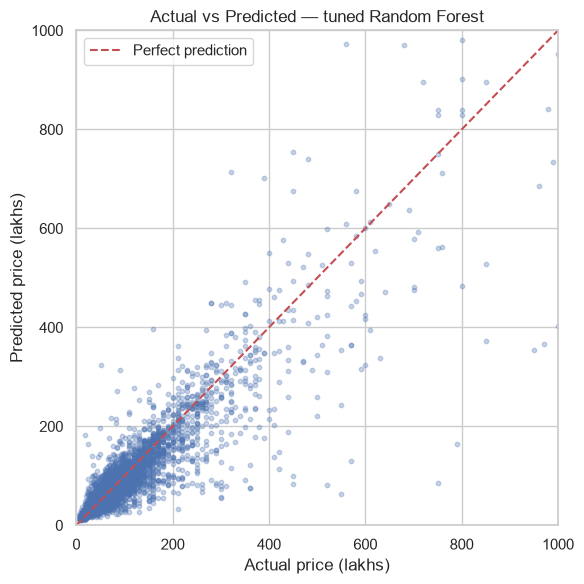

In [15]:
plt.figure(figsize=(6, 6))
plt.scatter(actual, pred, alpha=0.3, s=10)
lims = [0, 1000]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual price (lakhs)"); plt.ylabel("Predicted price (lakhs)")
plt.title("Actual vs Predicted — tuned Random Forest")
plt.legend()
plt.tight_layout()
plt.savefig("../images/actual_vs_predicted.png", dpi=120)
plt.show()

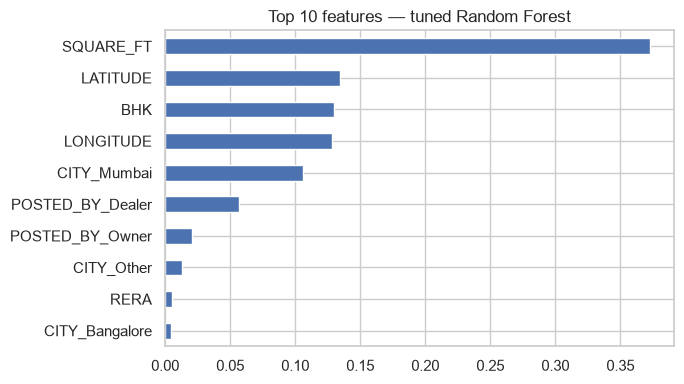

In [16]:
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)
importances.plot(kind="barh", figsize=(7, 4), title="Top 10 features — tuned Random Forest")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=120)
plt.show()

**What this shows:** the model's *percentage* error is fairly steady, but in lakhs the errors grow a lot for expensive homes, and a few big misses on luxury listings are what push the RMSE up. The dataset has no information on building age, floor, amenities or exact locality quality, which are exactly what separates one expensive home from another.

## Step 8 — Save a self-contained model and predict on a new house

In [17]:
city_coords = data.groupby("CITY")[["LATITUDE", "LONGITUDE"]].mean()

bundle = {
    "model": best_model,
    "columns": list(X.columns),
    "cities": sorted(data["CITY"].unique()),
    "city_coords": {c: (float(r.LATITUDE), float(r.LONGITUDE)) for c, r in city_coords.iterrows()},
    "metrics": {
        "r2_log": float(test_results["R2 on log price"]),
        "mae_lakhs": float(test_results["MAE (lakhs)"]),
        "median_pct_error": float(report["pct_err"].median()),
    },
}
joblib.dump(bundle, "../models/house_price_model.joblib", compress=3)

# Load it back the same way a separate app would — no training data needed
loaded = load_bundle("../models/house_price_model.joblib")
print("2 BHK, 1100 sqft, Pune     :", round(predict_price(loaded, 2, 1100, "Pune"), 1), "lakhs")
print("3 BHK, 1500 sqft, Bangalore:", round(predict_price(loaded, 3, 1500, "Bangalore"), 1), "lakhs")
print("2 BHK, 900 sqft, Chennai   :", round(predict_price(loaded, 2, 900, "Chennai"), 1), "lakhs")

2 BHK, 1100 sqft, Pune     : 79.3 lakhs
3 BHK, 1500 sqft, Bangalore: 78.7 lakhs
2 BHK, 900 sqft, Chennai   : 57.7 lakhs


## Limitations & next steps
- No building age, floor, amenities or exact locality quality in the data, so expensive homes are hard to price.
- `SQUARE_FT` appears to be derived from price (see Step 2), so test scores likely overstate real-world accuracy.
- City centres and radii for the city feature are approximate choices; a finer locality feature could help further.
- Cleaning limits were chosen by inspection, not from any official rule.
- **Ideas:** XGBoost/LightGBM, tuning Gradient Boosting too, locality-level features.